### pyAPES_MLM: Multi-layer soil-vegetation-atmosphere transfer model

Demo how to:
1. Set-up the model
1. Run the model
1. Retrieve the results using xarray

In [1]:
# setting path
import sys
import os
import pandas as pd
import numpy as np
from pyAPES.soil.heat import sinusoidal_soil_temperature

from dotenv import load_dotenv
load_dotenv()
pyAPES_main_folder = os.getenv('pyAPES_main_folder')
sys.path.append(pyAPES_main_folder)
os.chdir(pyAPES_main_folder)

### Import modules

In [2]:
# function to read forcing data. See 'forcing/forcing_info.txt' for model forcing variable names and units!
from pyAPES.utils.iotools import read_forcing

# import the multi-layer model (mlm) driver
from pyAPES.pyAPES_MLM import driver

eps = 1e-16

### Read model parameter dictionaries

- mlm setup (parameterization, forcing file & run info) defined in: pyAPES.models.mlm_parameters
- output variables & logger configuration defined in: pyAPES.models.mlm_outputs. This is read by driver

In [3]:
# import parameter dictionaries
from pyAPES.parameters.mlm_parameters_SE_Deg import gpara, cpara, spara # model configuration, canopy parameters, soil parameters

### Read forcing data and compile input for driver

- forcing is read into pd.DataFrame. Units must be correct!
- create parameter dictionary and provide it to driver

In [4]:
gpara['forc_filename'] = f'{pyAPES_main_folder}/forcing/SE-Deg/SE-Deg_forcing_2020-2023.dat'
gpara['start_time'] = '2022-06-01'
gpara['end_time'] = '2022-09-01'
gpara['start_doy'] = pd.to_datetime(gpara['start_time']).dayofyear
cpara['forestfloor']['snowpack']['snow_model'] = 'fsm2'

# Initialize soil temperature profile based on sinusoidal function
doy0 = gpara['start_doy']
zz = -np.cumsum(spara['grid']['dz'])
T_ini = sinusoidal_soil_temperature(
    z=zz,
    doy=doy0,
    T_mean=5.59,
    T_amplitude=8.62,
    thermal_diffusivity=5.93e-8,
)
spara['heat_model']['initial_condition']['temperature'] = T_ini

# Set properties for the Sphagnum layer
cpara['forestfloor']['bottom_layer_types']['Sphagnum']['optical_properties']['albedo']['PAR'] = 0.06
cpara['forestfloor']['bottom_layer_types']['Sphagnum']['optical_properties']['albedo']['NIR'] = 0.20
cpara['forestfloor']['bottom_layer_types']['Sphagnum']['roughness_height'] = 0.005
cpara['forestfloor']['bottom_layer_types']['Sphagnum']['water_retention']['saturated_conductivity'] = 3e-5

# Set freezing curve for the soil layers
spara['soil_properties']['freezing_curve'] = [0.1, 0.1, 0.1, 0.1, 0.1, 0.1,
                                               0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1]
spara['soil_properties']['saturated_conductivity_vertical'][0] = 3e-5

# Snow albedo decay (when ALBEDO=2)
cpara['forestfloor']['snowpack']['fsm2']['params']['tmlt'] = 7.2e5

forcing = read_forcing(
    forcing_file=gpara['forc_filename'],
    start_time=gpara['start_time'],
    end_time=gpara['end_time'],
    dt=gpara['dt']
)

params = {
    'general': gpara,   # model configuration
    'canopy': cpara,    # planttype, micromet, canopy, bottomlayer parameters
    'soil': spara,      # soil heat and water flow parameters
    'forcing': forcing  # forcing data
}

### Run the model

In [5]:
resultfile, Model = driver(parameters=params,
                           create_ncf=True,
                           result_file= 'testrun_summer.nc'
                          )

INFO pyAPES.pyAPES_MLM driver pyAPES_MLM simulation started. Number of simulations: 1
INFO pyAPES.soil.water __init__ Water balance in soil solved using: EQUILIBRIUM & HOOGHOUDT
INFO pyAPES.soil.heat __init__ Soil heat balance solved.
INFO pyAPES.canopy.mlm_canopy __init__ Eflow: True, WMA: False, Ebal: True
INFO pyAPES.microclimate.radiation __init__ Shortwave radiation model: ZHAOQUALLS
INFO pyAPES.microclimate.radiation __init__ Longwave radiation model: ZHAOQUALLS
INFO pyAPES.canopy.forestfloor __init__ Forestfloor has 1 bottomlayer types
INFO pyAPES.utils.iotools save_parameters_yaml Parameters saved to: /Users/jpnousu/Models/pyAPES_main/inputs/testrun_summer.yml
INFO pyAPES.pyAPES_MLM driver Running simulation number (start time 2026-10-16 13:05): 0
INFO pyAPES.pyAPES_MLM run Running simulation 0


0%.. 10%.. 20%.. 30%.. 40%.. 50%.. 60%.. 70%.. 80%.. 90%.. 

INFO pyAPES.pyAPES_MLM run Finished simulation 0, running time 67.85 seconds
INFO pyAPES.pyAPES_MLM driver Running time 67.85 seconds


100%


INFO pyAPES.pyAPES_MLM driver Ready! Results are in: /Users/jpnousu/Models/pyAPES_main/results/testrun_summer.nc


### Model run completed and results are in NetCDF-file.

### Read results using xarray
- we use function 'read_results' from pyAPES.utils.utils

- see https://docs.xarray.dev/en/stable/



In [6]:
from pyAPES.utils.iotools import read_results
import matplotlib.pyplot as plt
#resultfile = '/Users/jpnousu/Models/pyAPES_main/results/testrun_summer.nc'
# read simulation restuls to xarray dataset
results = read_results(resultfile)

In [7]:
met = f'{pyAPES_main_folder}/forcing/SE-Deg/SE-Deg_meteo_2020-2023.dat'
flux = f'{pyAPES_main_folder}/forcing/SE-Deg/SE-Deg_EC_2020-2023.dat'
start = pd.to_datetime(str(results['date'][0].values))
end = pd.to_datetime(str(results['date'][-1].values))
meteo = pd.read_csv(met, sep=';', index_col=0, parse_dates=True)
fluxes = pd.read_csv(flux, sep=';', index_col=0, parse_dates=True)
meteo = meteo[start:end]
fluxes = fluxes[start:end]
meteo.index.name = 'date'
fluxes.index.name = 'date'

In [8]:
#Time window to plot
plot_start = '2022-06-01'
plot_end = '2022-09-01'
simulation = 0

# Resampling period (default daily)
resample_period = '0.5h'
#resample_period = '6h'
#resample_period = '1D'

canopy_cols_raw = ['canopy_SH', 'canopy_Rnet', 'canopy_LE']
canopy_extra_cols = ['canopy_SWnet', 'canopy_LWnet']
ffloor_cols = ['ffloor_sensible_heat', 'ffloor_net_radiation', 'ffloor_latent_heat', 'ffloor_ground_heat']
all_flux_cols = canopy_cols_raw + canopy_extra_cols + ffloor_cols

results_flux = results[all_flux_cols].sel(simulation=simulation).sel(date=slice(plot_start, plot_end))

# Sign convention: positive upward turbulent fluxes
results_flux['canopy_SH'] *= -1
results_flux['canopy_LE'] *= -1
results_flux['ffloor_sensible_heat'] *= -1
results_flux['ffloor_latent_heat'] *= -1
results_flux['ffloor_ground_heat'] *= -1

# Rename canopy heat flux columns
results_flux = results_flux.rename({
    'canopy_SH': 'canopy_sensible_heat',
    'canopy_LE': 'canopy_latent_heat',
    'canopy_Rnet': 'canopy_net_radiation'
})
canopy_cols = ['canopy_sensible_heat', 'canopy_net_radiation', 'canopy_latent_heat']

# Resampled mean fluxes
results_flux = results_flux.resample(date=resample_period).mean().to_dataframe()[
    canopy_cols + canopy_extra_cols + ffloor_cols
]
swe = results['ffloor_snow_water_equivalent'].sel(simulation=simulation).sel(
    date=slice(plot_start, plot_end)
).resample(date=resample_period).mean().to_dataframe()['ffloor_snow_water_equivalent']

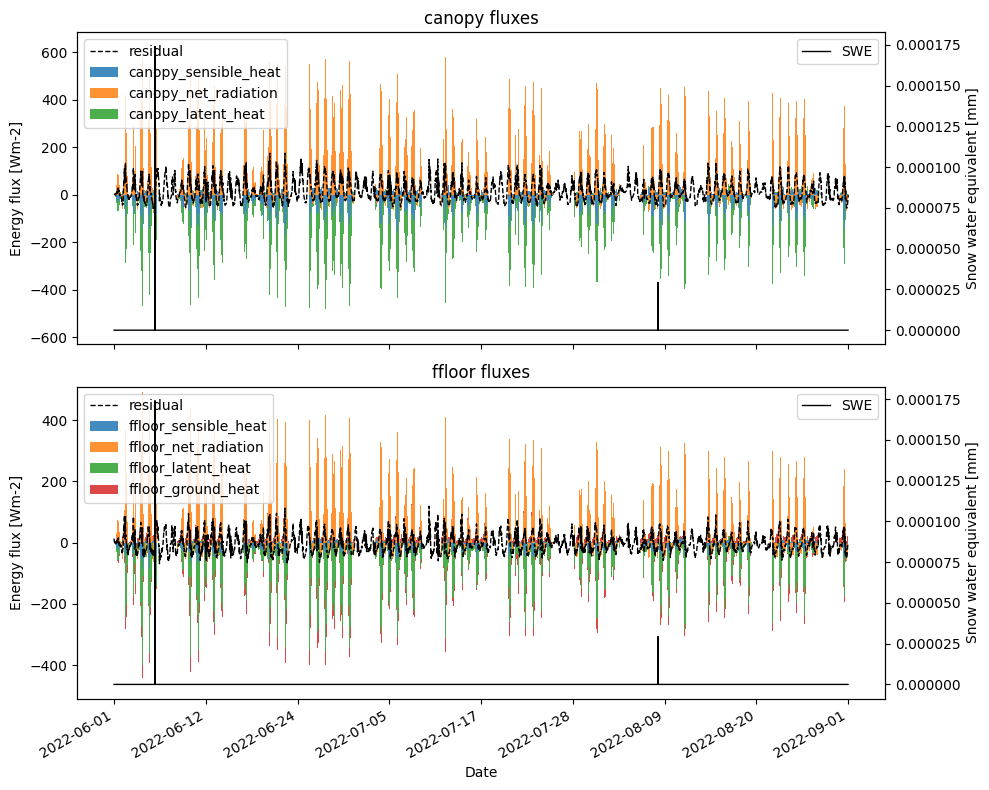

In [9]:
def plot_stacked_fluxes(ax, df, cols, title):
    pos = df[cols].clip(lower=0)
    neg = df[cols].clip(upper=0)

    idx = pos.index.union(neg.index)
    pos = pos.reindex(idx).fillna(0.0)
    neg = neg.reindex(idx).fillna(0.0)

    residual = df[cols].sum(axis=1).reindex(idx)

    x = np.arange(len(idx))
    width = 0.7
    pos_bottom = np.zeros(len(idx))
    neg_bottom = np.zeros(len(idx))

    cycle = plt.rcParams['axes.prop_cycle'].by_key().get('color', [])
    colors = {c: cycle[i % len(cycle)] for i, c in enumerate(cols)}

    for col in cols:
        y = pos[col].to_numpy()
        ax.bar(x, y, bottom=pos_bottom, width=width, alpha=0.85, color=colors[col], label=col)
        pos_bottom += y

    for col in cols:
        y = neg[col].to_numpy()
        ax.bar(x, y, bottom=neg_bottom, width=width, alpha=0.85, color=colors[col])
        neg_bottom += y

    ax.plot(x, residual.to_numpy(), color='black', linewidth=1.0, linestyle='--', label='residual')
    ax.set_ylabel('Energy flux [Wm-2]')
    ax.set_title(title)
    ax.legend(loc='upper left')

    return idx, x

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

idx, x = plot_stacked_fluxes(axes[0], results_flux, canopy_cols, 'canopy fluxes')
_, _ = plot_stacked_fluxes(axes[1], results_flux, ffloor_cols, 'ffloor fluxes')

# Secondary axis for snow water equivalent on both panels
swe_aligned = swe.reindex(idx)
ax1_2 = axes[0].twinx()
ax1_2.plot(x, swe_aligned.to_numpy(), linewidth=1.0, color='black', linestyle='-', label='SWE')
ax1_2.set_ylabel('Snow water equivalent [mm]')
ax1_2.legend(loc='upper right')

ax2 = axes[1].twinx()
ax2.plot(x, swe_aligned.to_numpy(), linewidth=1.0, color='black', linestyle='-', label='SWE')
ax2.set_ylabel('Snow water equivalent [mm]')
ax2.legend(loc='upper right')

tick_step = max(1, len(idx) // 8)
axes[1].set_xticks(x[::tick_step])
axes[1].set_xticklabels([d.strftime("%Y-%m-%d") for d in idx[::tick_step]], rotation=30, ha="right")
axes[1].set_xlabel('Date')

plt.tight_layout()

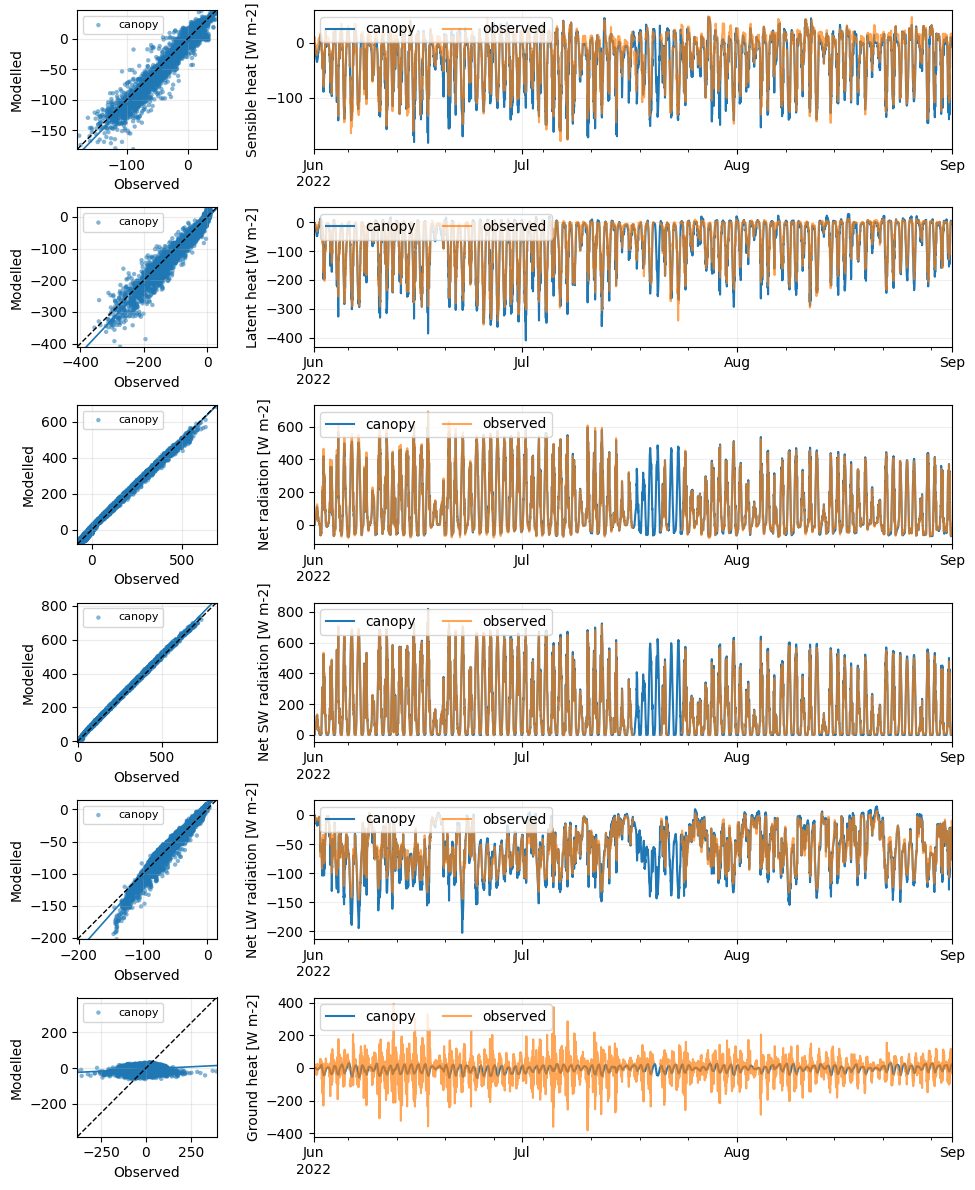

In [10]:
# Resample observed fluxes to daily and slice to match modelled index
start = pd.to_datetime(results_flux.index[0])
end = pd.to_datetime(results_flux.index[-1])

fluxes_resampled = fluxes.resample(resample_period).mean()[start:end]
results_flux_resampled = results_flux.resample(resample_period).mean()[start:end]

# Compute observed radiation components
fluxes_resampled['Rnet_obs']  = (fluxes_resampled['SW_IN_F'] - fluxes_resampled['SW_OUT'] +
                                 fluxes_resampled['LW_IN_F'] - fluxes_resampled['LW_OUT'])
fluxes_resampled['SWnet_obs'] = fluxes_resampled['SW_IN_F'] - fluxes_resampled['SW_OUT']
fluxes_resampled['LWnet_obs'] = fluxes_resampled['LW_IN_F'] - fluxes_resampled['LW_OUT']

# Fix sign convention for observed H and LE
fluxes_resampled.loc[fluxes_resampled['H_F_MDS_QC'] >= 1.5, 'H_F_MDS'] = np.nan
fluxes_resampled.loc[fluxes_resampled['LE_F_MDS_QC'] >= 1.5, 'LE_F_MDS'] = np.nan
fluxes_resampled.loc[fluxes_resampled['G_F_MDS_QC'] >= 1.5, 'G_F_MDS'] = np.nan
fluxes_resampled['H_F_MDS']  *= -1
fluxes_resampled['LE_F_MDS'] *= -1
fluxes_resampled['G_F_MDS'] *= -1

# Pairs: (canopy modelled, ffloor modelled, observed, y-axis label)
pairs = [
    ('canopy_sensible_heat', 'ffloor_sensible_heat', 'H_F_MDS',   'Sensible heat [W m-2]'),
    ('canopy_latent_heat',   'ffloor_latent_heat',   'LE_F_MDS',  'Latent heat [W m-2]'),
    ('canopy_net_radiation', 'ffloor_net_radiation', 'Rnet_obs',  'Net radiation [W m-2]'),
    ('canopy_SWnet',         None,                   'SWnet_obs', 'Net SW radiation [W m-2]'),
    ('canopy_LWnet',         None,                   'LWnet_obs', 'Net LW radiation [W m-2]'),
    ('ffloor_ground_heat', 'ffloor_ground_heat', 'G_F_MDS', 'Ground heat [W m-2]'),
]

n = len(pairs)
fig, axes = plt.subplots(
    n, 2, figsize=(10, 2 * n), squeeze=False,
    sharex=False,
    gridspec_kw={'width_ratios': [1, 3]}
)

for i, (canopy_col, ffloor_col, obs_col, ylabel) in enumerate(pairs):
    ax_sc = axes[i, 0]
    ax_ts = axes[i, 1]

    obs_aligned = fluxes_resampled[obs_col].reindex(results_flux.index)

    # --- Left: 1:1 scatter (modelled vs observed) ---
    paired_can = pd.concat(
        [obs_aligned, results_flux_resampled[canopy_col]],
        axis=1, keys=['observed', 'canopy']
    ).dropna()

    paired_ff = None
    if ffloor_col is not None and ffloor_col in results_flux.columns:
        paired_ff = pd.concat(
            [obs_aligned, results_flux_resampled[ffloor_col]],
            axis=1, keys=['observed', 'ffloor']
        ).dropna()

    has_can = len(paired_can) > 0
    has_ff = paired_ff is not None and len(paired_ff) > 0

    if has_can or has_ff:
        mins = []
        maxs = []
        if has_can:
            mins.extend([paired_can['observed'].min(), paired_can['canopy'].min()])
            maxs.extend([paired_can['observed'].max(), paired_can['canopy'].max()])
        if has_ff:
            mins.extend([paired_ff['observed'].min(), paired_ff['ffloor'].min()])
            maxs.extend([paired_ff['observed'].max(), paired_ff['ffloor'].max()])

        vmin = np.nanmin(mins)
        vmax = np.nanmax(maxs)

        if has_can:
            x_obs_can = paired_can['observed'].to_numpy()
            y_can = paired_can['canopy'].to_numpy()
            ax_sc.scatter(
                x_obs_can, y_can, s=10, alpha=0.55, edgecolors='none',
                color='tab:blue', label='canopy'
            )
            if len(paired_can) >= 2 and np.nanstd(x_obs_can) > 0:
                slope, intercept = np.polyfit(x_obs_can, y_can, 1)
                ax_sc.plot(
                    [vmin, vmax],
                    [slope * vmin + intercept, slope * vmax + intercept],
                    color='tab:blue', linewidth=1.2, linestyle='-'
                )

        #if has_ff:
            #x_obs_ff = paired_ff['observed'].to_numpy()
            #y_ff = paired_ff['ffloor'].to_numpy()
            #ax_sc.scatter(
            #    x_obs_ff, y_ff, s=10, alpha=0.55, edgecolors='none',
            #    color='tab:green', label='ffloor'
            #)
            #if len(paired_ff) >= 2 and np.nanstd(x_obs_ff) > 0:
            #    slope_ff, intercept_ff = np.polyfit(x_obs_ff, y_ff, 1)
            #    ax_sc.plot(
            #        [vmin, vmax],
            #        [slope_ff * vmin + intercept_ff, slope_ff * vmax + intercept_ff],
            #        color='tab:green', linewidth=1.2, linestyle='-')

        ax_sc.plot([vmin, vmax], [vmin, vmax], 'k--', linewidth=1.0)
        ax_sc.set_xlim(vmin, vmax)
        ax_sc.set_ylim(vmin, vmax)
        ax_sc.legend(loc='best', fontsize=8)
    else:
        ax_sc.text(0.5, 0.5, 'No overlap', ha='center', va='center', transform=ax_sc.transAxes)

    ax_sc.set_aspect('equal', adjustable='box')
    #ax_sc.set_title(ylabel)
    ax_sc.set_xlabel('Observed')
    ax_sc.set_ylabel('Modelled')
    ax_sc.grid(alpha=0.25)

    # --- Right: time series ---
    results_flux_resampled[canopy_col].plot(ax=ax_ts, label='canopy', linestyle='-', color='tab:blue')
    #if ffloor_col is not None and ffloor_col in results_flux_resampled.columns:
        #results_flux_resampled[ffloor_col].plot(ax=ax_ts, label='ffloor', linestyle='--', color='tab:green')
    fluxes_resampled[obs_col].plot(ax=ax_ts, label='observed', alpha=0.7, color='tab:orange')
    ax_ts.set_ylabel(ylabel)
    ax_ts.set_title('')
    ax_ts.set_xlabel('')
    ax_ts.legend(ncol=3, loc='upper left')
    ax_ts.grid(alpha=0.2)

plt.tight_layout()
filename = r'/Users/jpnousu/Library/CloudStorage/OneDrive-Luonnonvarakeskus/pyAPES_figs/energy_fluxes_summer.png'
plt.savefig(filename, dpi=300, bbox_inches='tight')

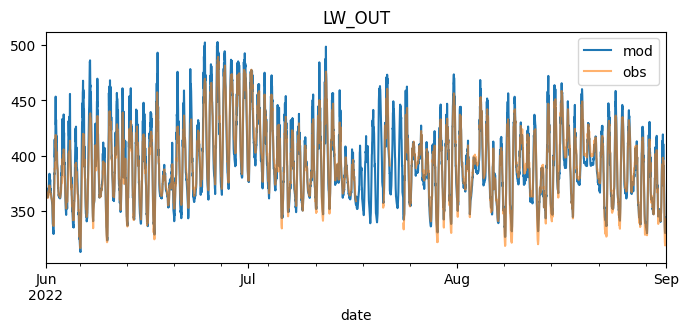

In [11]:
plt.figure(0, figsize=(8, 3))
((results_flux['canopy_LWnet']*-1) + fluxes['LW_IN_F']).plot(label='mod')
fluxes['LW_OUT'].plot(label='obs', alpha=0.6)
plt.title('LW_OUT')
plt.legend()

/opt/miniconda3/envs/pyapes/lib/python3.14/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


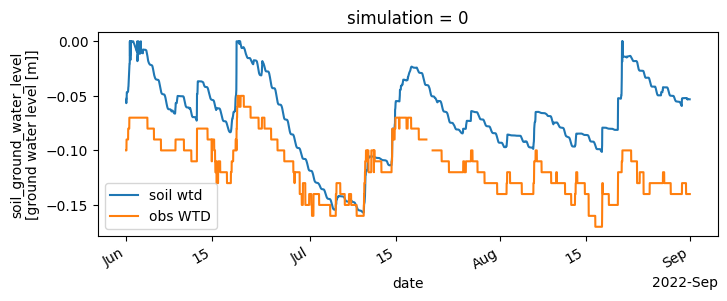

In [12]:
plt.figure(0, figsize=(8, 3))
results['soil_ground_water_level'][:,0].plot(label='soil wtd')
meteo['WTD'].plot(label='obs WTD')
plt.legend()
filename = r'/Users/jpnousu/Library/CloudStorage/OneDrive-Luonnonvarakeskus/pyAPES_figs/soil_wtd_summer.png'
plt.savefig(filename, dpi=300, bbox_inches='tight')
plt.show()

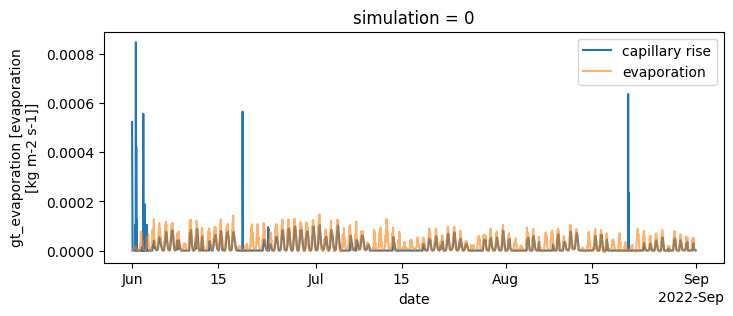

In [13]:
plt.figure(figsize=(8, 3))
results['gt_capillary_rise'].plot(label='capillary rise')
results['gt_evaporation'].plot(alpha=0.6, label='evaporation')
plt.legend()

Observation depth: -0.02, comparison depth: 0.039999999999999994, using gt_temperature
Observation depth: -0.05, comparison depth: 0.009999999999999995, using gt_temperature
Observation depth: -0.1, comparison depth: -0.04000000000000001, Model depth index: 3, model depth: -0.03500000014901161
Observation depth: -0.15, comparison depth: -0.09, Model depth index: 9, model depth: -0.0949999988079071
Observation depth: -0.3, comparison depth: -0.24, Model depth index: 16, model depth: -0.23000000417232513
Observation depth: -0.5, comparison depth: -0.44, Model depth index: 22, model depth: -0.42500001192092896


/opt/miniconda3/envs/pyapes/lib/python3.14/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)
/opt/miniconda3/envs/pyapes/lib/python3.14/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)
/opt/miniconda3/envs/pyapes/lib/python3.14/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)
/opt/miniconda3/envs/pyapes/lib/python3.14/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)
/opt/miniconda3/envs/pyapes/lib/python3.14/site-pack

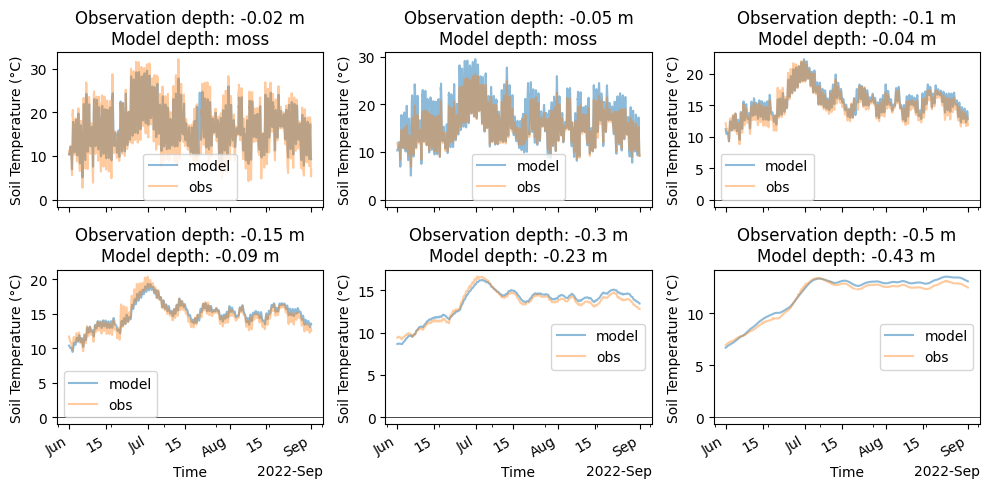

In [14]:
cutoff_depth = -0.06
model_depth_offset = 0.06

t_obs = {
    'TS_1': -0.02,
    'TS_2': -0.05,
    'TS_3': -0.1,
    'TS_4': -0.15,
    'TS_5': -0.3,
    'TS_6': -0.5
}

fig, axes = plt.subplots(2, 3, figsize=(10, 5), sharex=True)
axes = axes.flatten()

for ax, (key, depth) in zip(axes, t_obs.items()):

    comparison_depth = depth + model_depth_offset

    if depth > cutoff_depth:
        print(
            f"Observation depth: {depth}, comparison depth: {comparison_depth}, "
            "using gt_temperature"
        )

        results['gt_temperature'][:, 0, 0].plot(
            ax=ax, label='model', alpha=0.5
        )

        title = (
            f"Observation depth: {depth} m\n"
            f"Model depth: moss"
        )

    else:
        model_depth = np.argmin(
            np.abs(results['soil_z'].values - comparison_depth)
        )

        title_depth = results['soil_z'][model_depth].values

        print(
            f"Observation depth: {depth}, comparison depth: {comparison_depth}, "
            f"Model depth index: {model_depth}, model depth: {title_depth}"
        )

        results['soil_temperature'][:, 0, model_depth].plot(
            ax=ax, label='model', alpha=0.5
        )

        title = (
            f"Observation depth: {depth} m\n"
            f"Model depth: {title_depth:.2f} m"
        )

    meteo[key].plot(
        ax=ax, label='obs', alpha=0.4
    )

    ax.axhline(y=0, color='k', lw=0.5)
    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel("Soil Temperature (°C)")
    ax.legend()

plt.tight_layout()
filename = r'/Users/jpnousu/Library/CloudStorage/OneDrive-Luonnonvarakeskus/pyAPES_figs/soil_temps_summer.png'
plt.savefig(filename, dpi=300, bbox_inches='tight')
plt.show()

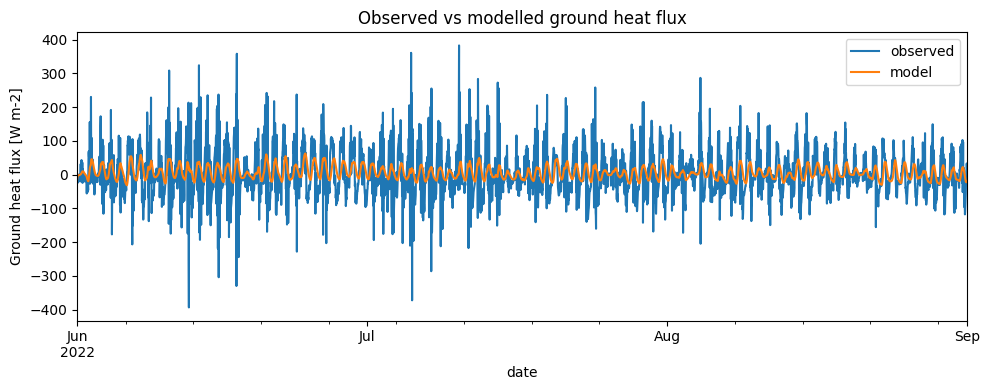

In [15]:
plot_start = '2022-06-01'
plot_end = '2022-09-01'

fig, ax = plt.subplots(figsize=(10, 4))

obs_ground_heat = fluxes.loc[plot_start:plot_end, 'G_F_MDS'].rename('observed')
model_ground_heat = (
    results['ffloor_ground_heat']
    .sel(simulation=0)
    .sel(date=slice(plot_start, plot_end))
    .to_series()
    .rename('model')
)

comparison = pd.concat([obs_ground_heat, model_ground_heat], axis=1)
comparison.plot(ax=ax)
ax.set_ylabel('Ground heat flux [W m-2]')
ax.set_title('Observed vs modelled ground heat flux')
ax.legend()
plt.tight_layout()
filename = r'/Users/jpnousu/Library/CloudStorage/OneDrive-Luonnonvarakeskus/pyAPES_figs/ground_heat_summer.png'
plt.savefig(filename, dpi=300, bbox_inches='tight')
plt.show()

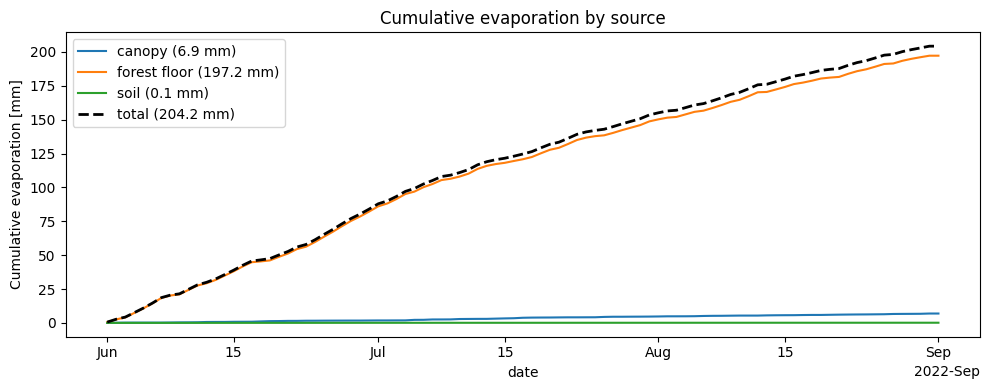

In [16]:
conv_per_seconds_to_day = 86400  # original data in kg m-2 s-1 -> mm day-1
# compiling data

daily_evap = (
    results[["canopy_evaporation", "ffloor_evaporation", "soil_evaporation"]]
    .sel(simulation=simulation)
    .sel(date=slice(plot_start, plot_end))
    .resample(date='D')
    .mean()
    * conv_per_seconds_to_day
)

canopy_evap = daily_evap['canopy_evaporation'].cumsum(dim='date')
ffloor_evap = daily_evap['ffloor_evaporation'].cumsum(dim='date')
soil_evap = daily_evap['soil_evaporation'].cumsum(dim='date')
total_evap = canopy_evap + ffloor_evap + soil_evap

canopy_total = float(canopy_evap.isel(date=-1))
ffloor_total = float(ffloor_evap.isel(date=-1))
soil_total = float(soil_evap.isel(date=-1))
total_total = float(total_evap.isel(date=-1))

# plotting cumulative evaporation in mm
fig, ax = plt.subplots(figsize=(10, 4))
canopy_evap.plot(ax=ax, label=f'canopy ({canopy_total:.1f} mm)')
ffloor_evap.plot(ax=ax, label=f'forest floor ({ffloor_total:.1f} mm)')
soil_evap.plot(ax=ax, label=f'soil ({soil_total:.1f} mm)')
total_evap.plot(ax=ax, label=f'total ({total_total:.1f} mm)', color='black', linewidth=2, linestyle='--')
ax.set_ylabel('Cumulative evaporation [mm]')
ax.set_title('Cumulative evaporation by source')
ax.legend()
plt.tight_layout()